## Libraries

In [2]:
from utils.data_loader import load_mnist
from utils.plots import plot_sample_images, plot_training_history
from utils.models import build_lenet5_mnist

## Loading MNIST dataset

In [3]:
(X_train_lenet5_mnist, y_train_lenet5_mnist), (X_test_lenet5_mnist, y_test_lenet5_mnist) = load_mnist(flatten=False)
print(f"X_train: {X_train_lenet5_mnist.shape}, y_train: {y_train_lenet5_mnist.shape}")
print(f"X_test: {X_test_lenet5_mnist.shape}, y_test: {y_test_lenet5_mnist.shape}")

X_train: (60000, 28, 28, 1), y_train: (60000, 10)
X_test: (10000, 28, 28, 1), y_test: (10000, 10)


## Show MNIST dataset images 

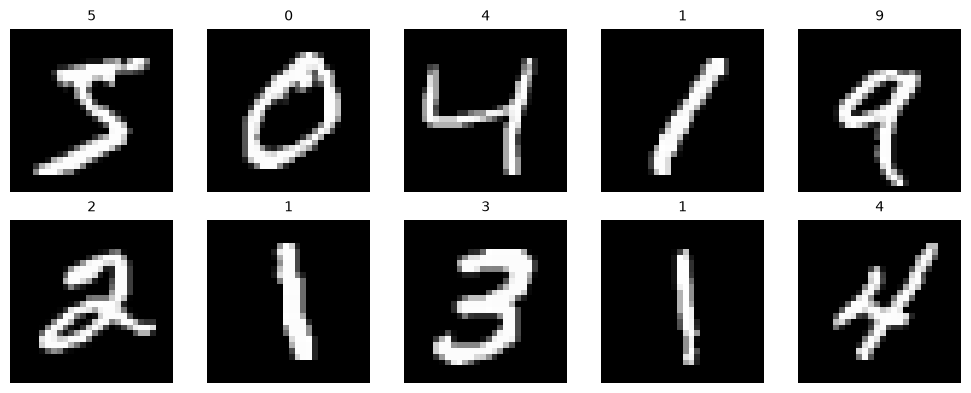

In [4]:
plot_sample_images(X_train_lenet5_mnist[:10], y_train_lenet5_mnist[:10])


## Model implementation and training

In [5]:
lenet_mnist = build_lenet5_mnist(learning_rate=0.001)
lenet_mnist.summary()

E0000 00:00:1791671444.843099   11380 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Entraînement
history_lenet = lenet_mnist.fit(
    X_train_lenet5_mnist,
    y_train_lenet5_mnist,
    validation_data=(X_test_lenet5_mnist, y_test_lenet5_mnist),
    epochs=10,
    batch_size=64
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 13ms/step - accuracy: 0.9182 - loss: 0.2762 - val_accuracy: 0.9689 - val_loss: 0.0964
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.9737 - loss: 0.0862 - val_accuracy: 0.9809 - val_loss: 0.0602
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9810 - loss: 0.0620 - val_accuracy: 0.9829 - val_loss: 0.0536
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.9849 - loss: 0.0486 - val_accuracy: 0.9868 - val_loss: 0.0390
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9876 - loss: 0.0397 - val_accuracy: 0.9875 - val_loss: 0.0399
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9894 - loss: 0.0333 - val_accuracy: 0.9888 - val_loss: 0.0359
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9907 - loss: 0.0292 - val_accuracy: 0.9897 - val_loss: 0.0342
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9919 - loss: 0.0255 - 

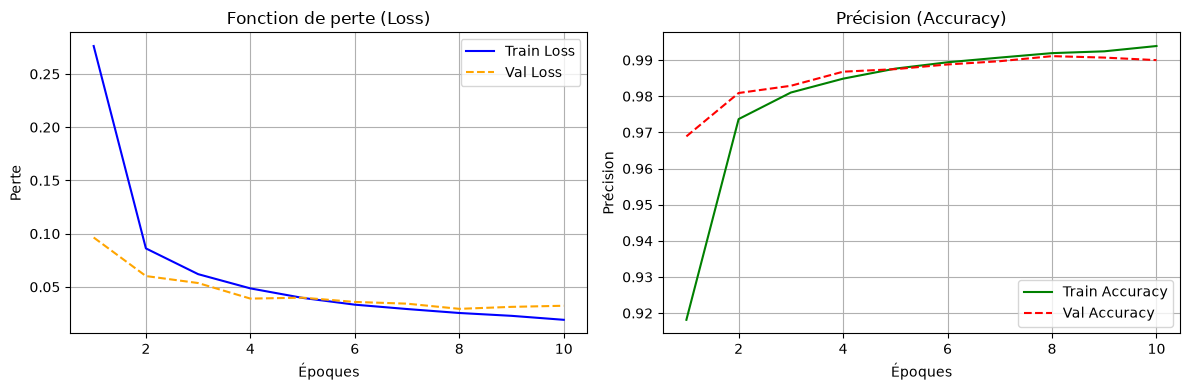

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9900 - loss: 0.0323
Précision LeNet-5 sur MNIST : 99.00%


In [7]:
plot_training_history(history_lenet)

test_loss, test_acc = lenet_mnist.evaluate(X_test_lenet5_mnist, y_test_lenet5_mnist)
print(f"Précision LeNet-5 sur MNIST : {test_acc * 100:.2f}%")